# Chapter 3: Feature Engineering

> **Data** volunteers.csv  (exercises use clinic_referrals.csv) · **Time** 45 min · **Needs first** C1, C2

## What you will be able to do

1. Build new numeric features from arithmetic on existing columns
2. Extract year, month, dayofweek and quarter from a datetime column
3. Turn free text into features with CountVectorizer and TfidfVectorizer
4. Bin a continuous column with pd.cut and pd.qcut, and say which one fits
5. Generate interaction and polynomial terms, and state the cost in columns

## The one idea to hold on to

A column can hold real signal in a shape no model can use. Feature engineering is changing the shape, not inventing the signal.

Welcome to the Feature Engineering chapter! Feature engineering is often considered the **most important step** in the machine learning pipeline. It involves transforming raw data into features that better represent the underlying problem, leading to improved model accuracy.

---

## What is Feature Engineering?

**Feature Engineering** is the process of using domain knowledge to extract, transform, and create new features (variables) from raw data that make machine learning algorithms work better.

![Feature Engineering Overview](https://miro.medium.com/v2/resize:fit:1400/1*p3jlS0M2AoKNZlyWxfxuNA.png)

*The feature engineering process transforms raw data into meaningful features for ML models.*

### Why is Feature Engineering Important?

| Benefit | Description |
| :--- | :--- |
| **Improved Accuracy** | Well-engineered features can significantly boost model performance |
| **Reduced Overfitting** | Proper features help models generalize better |
| **Faster Training** | Relevant features reduce computational complexity |
| **Better Interpretability** | Meaningful features make models easier to understand |

> "Coming up with features is difficult, time-consuming, and requires expert knowledge. Applied machine learning is basically feature engineering." - Andrew Ng

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import PolynomialFeatures
import warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 50)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Loading the Dataset

We will work with the `volunteers.csv` dataset, which contains information about volunteer opportunities in New York City.

In [2]:
# Load the dataset
df = pd.read_csv('../../00-data/volunteers.csv')

# Display first few rows
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (665, 35)


,opportunity_id,content_id,vol_requests,event_time,title,hits,summary,is_priority,category_id,category_desc,amsl,amsl_unit,org_title,org_content_id,addresses_count,locality,region,postalcode,primary_loc,display_url,recurrence_type,hours,created_date,last_modified_date,start_date_date,end_date_date,status,Latitude,Longitude,Community Board,Community Council,Census Tract,BIN,BBL,NTA
0,4996,37004,50,0,Volunteers Needed For Rise Up & Stay Put! Home...,737,Building on successful events last summer and ...,NaN,NaN,NaN,NaN,NaN,Center For NYC Neighborhoods,4426,1,NaN,NY,NaN,NaN,/opportunities/4996,onetime,0,January 13 2011,June 23 2011,July 30 2011,July 30 2011,approved,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,5008,37036,2,0,Web designer,22,Build a website for an Afghan business,NaN,1.0,Strengthening Communities,NaN,NaN,Bpeace,37026,1,"5 22nd St\nNew York, NY 10010\n(40.74053152272...",NY,10010.0,NaN,/opportunities/5008,onetime,0,January 14 2011,January 25 2011,February 01 2011,February 01 2011,approved,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5016,37143,20,0,Urban Adventures - Ice Skating at Lasker Rink,62,Please join us and the students from Mott Hall...,NaN,1.0,Strengthening Communities,NaN,NaN,Street Project,3001,1,NaN,NY,10026.0,NaN,/opportunities/5016,onetime,0,January 19 2011,January 21 2011,January 29 2011,January 29 2011,approved,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5022,37237,500,0,Fight global hunger and support women farmers ...,14,The Oxfam Action Corps is a group of dedicated...,NaN,1.0,Strengthening Communities,NaN,NaN,Oxfam America,2170,1,NaN,NY,2114.0,NaN,/opportunities/5022,ongoing,0,January 21 2011,January 25 2011,February 14 2011,March 31 2012,approved,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5055,37425,15,0,Stop 'N' Swap,31,Stop 'N' Swap reduces NYC's waste by finding n...,NaN,4.0,Environment,NaN,NaN,Office of Recycling Outreach and Education,36773,1,NaN,NY,10455.0,NaN,/opportunities/5055,onetime,0,January 28 2011,February 01 2011,February 05 2011,February 05 2011,approved,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Check data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 665 entries, 0 to 664
Data columns (total 35 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   opportunity_id      665 non-null    int64  
 1   content_id          665 non-null    int64  
 2   vol_requests        665 non-null    int64  
 3   event_time          665 non-null    int64  
 4   title               665 non-null    object 
 5   hits                665 non-null    int64  
 6   summary             665 non-null    object 
 7   is_priority         62 non-null     object 
 8   category_id         617 non-null    float64
 9   category_desc       617 non-null    object 
 10  amsl                0 non-null      float64
 11  amsl_unit           0 non-null      float64
 12  org_title           665 non-null    object 
 13  org_content_id      665 non-null    int64  
 14  addresses_count     665 non-null    int64  
 15  locality            595 non-null    object 
 16  region  

In [4]:
# Check column names
print("Columns in the dataset:")
for i, col in enumerate(df.columns):
    print(f"{i+1}. {col}")

Columns in the dataset:
1. opportunity_id
2. content_id
3. vol_requests
4. event_time
5. title
6. hits
7. summary
8. is_priority
9. category_id
10. category_desc
11. amsl
12. amsl_unit
13. org_title
14. org_content_id
15. addresses_count
16. locality
17. region
18. postalcode
19. primary_loc
20. display_url
21. recurrence_type
22. hours
23. created_date
24. last_modified_date
25. start_date_date
26. end_date_date
27. status
28. Latitude
29. Longitude
30. Community Board
31. Community Council 
32. Census Tract
33. BIN
34. BBL
35. NTA


---

## 2. Feature Creation from Existing Data

One of the most powerful feature engineering techniques is **creating new features** by combining or transforming existing ones.

![Feature Creation](https://www.researchgate.net/publication/344645696/figure/fig1/AS:945715506655241@1602477254963/Feature-engineering-pipeline.png)

*Creating new features from existing data can reveal hidden patterns.*

### 2.1 Mathematical Operations

We can create features using arithmetic operations on numerical columns.

In [5]:
# Create a copy to work with
df_eng = df.copy()

# Create feature: hits per volunteer request ratio
# This shows how popular each opportunity is relative to the volunteers needed
df_eng['hits_per_request'] = df_eng['hits'] / (df_eng['vol_requests'] + 1)  # +1 to avoid division by zero

print("New feature 'hits_per_request' created!")
df_eng[['title', 'hits', 'vol_requests', 'hits_per_request']].head(10)

New feature 'hits_per_request' created!


,title,hits,vol_requests,hits_per_request
0,Volunteers Needed For Rise Up & Stay Put! Home...,737,50,14.450980
1,Web designer,22,2,7.333333
2,Urban Adventures - Ice Skating at Lasker Rink,62,20,2.952381
3,Fight global hunger and support women farmers ...,14,500,0.027944
4,Stop 'N' Swap,31,15,1.937500
5,Queens Stop 'N' Swap,135,15,8.437500
6,Staff Development Trainer,156,2,52.000000
7,CLARO Brooklyn Volunteer Attorney,4407,20,209.857143
8,Join Cents Ability!,325,100,3.217822
9,Volunteer-Community Health Advocates,928,1,464.000000


In [6]:
# Create a feature indicating if the opportunity has high engagement
# Using the median as threshold
median_hits = df_eng['hits'].median()
df_eng['high_engagement'] = (df_eng['hits'] > median_hits).astype(int)

print(f"Median hits: {median_hits}")
print("\nDistribution of high_engagement:")
print(df_eng['high_engagement'].value_counts())

Median hits: 204.0

Distribution of high_engagement:
high_engagement
0    333
1    332
Name: count, dtype: int64


### 2.2 String/Text Manipulation

We can extract useful information from text columns.

In [7]:
# Create feature: length of the title
df_eng['title_length'] = df_eng['title'].str.len()

# Create feature: word count in title
df_eng['title_word_count'] = df_eng['title'].str.split().str.len()

# Create feature: length of summary
df_eng['summary_length'] = df_eng['summary'].fillna('').str.len()

print("Text-based features created!")
df_eng[['title', 'title_length', 'title_word_count', 'summary_length']].head()

Text-based features created!


,title,title_length,title_word_count,summary_length
0,Volunteers Needed For Rise Up & Stay Put! Home...,59,11,291
1,Web designer,12,2,38
2,Urban Adventures - Ice Skating at Lasker Rink,45,8,114
3,Fight global hunger and support women farmers ...,83,15,281
4,Stop 'N' Swap,13,3,171


---

## 3. DateTime Feature Engineering

Datetime columns contain rich information that can be extracted into multiple meaningful features.

![DateTime Features](https://miro.medium.com/v2/resize:fit:1400/format:webp/1*X7NYLmVlLNp9zGCdTPNwsQ.png)

*Extracting temporal features from datetime columns.*

### Common DateTime Features:
- Year, Month, Day
- Day of Week
- Hour, Minute
- Is Weekend
- Quarter
- Time since a reference date

In [8]:
# Check date columns
date_cols = ['created_date', 'start_date_date', 'end_date_date', 'last_modified_date']
print("Sample date values:")
df_eng[date_cols].head()

Sample date values:


,created_date,start_date_date,end_date_date,last_modified_date
0,January 13 2011,July 30 2011,July 30 2011,June 23 2011
1,January 14 2011,February 01 2011,February 01 2011,January 25 2011
2,January 19 2011,January 29 2011,January 29 2011,January 21 2011
3,January 21 2011,February 14 2011,March 31 2012,January 25 2011
4,January 28 2011,February 05 2011,February 05 2011,February 01 2011


In [9]:
# Convert date columns to datetime
for col in date_cols:
    df_eng[col] = pd.to_datetime(df_eng[col], format='%B %d %Y', errors='coerce')

print("Date columns converted to datetime!")
df_eng[date_cols].dtypes

Date columns converted to datetime!


created_date          datetime64[ns]
start_date_date       datetime64[ns]
end_date_date         datetime64[ns]
last_modified_date    datetime64[ns]
dtype: object

In [10]:
# Extract datetime features from 'start_date_date'
df_eng['start_year'] = df_eng['start_date_date'].dt.year
df_eng['start_month'] = df_eng['start_date_date'].dt.month
df_eng['start_day'] = df_eng['start_date_date'].dt.day
df_eng['start_dayofweek'] = df_eng['start_date_date'].dt.dayofweek  # 0=Monday, 6=Sunday
df_eng['start_is_weekend'] = (df_eng['start_dayofweek'] >= 5).astype(int)
df_eng['start_quarter'] = df_eng['start_date_date'].dt.quarter

print("DateTime features extracted!")
df_eng[['start_date_date', 'start_year', 'start_month', 'start_day', 
        'start_dayofweek', 'start_is_weekend', 'start_quarter']].head(10)

DateTime features extracted!


,start_date_date,start_year,start_month,start_day,start_dayofweek,start_is_weekend,start_quarter
0,2011-07-30,2011,7,30,5,1,3
1,2011-02-01,2011,2,1,1,0,1
2,2011-01-29,2011,1,29,5,1,1
3,2011-02-14,2011,2,14,0,0,1
4,2011-02-05,2011,2,5,5,1,1
5,2011-02-12,2011,2,12,5,1,1
6,2011-01-27,2011,1,27,3,0,1
7,2011-02-07,2011,2,7,0,0,1
8,2011-02-08,2011,2,8,1,0,1
9,2011-02-14,2011,2,14,0,0,1


In [11]:
# Create feature: duration of the opportunity (in days)
df_eng['duration_days'] = (df_eng['end_date_date'] - df_eng['start_date_date']).dt.days

# Create feature: days from creation to start
df_eng['days_to_start'] = (df_eng['start_date_date'] - df_eng['created_date']).dt.days

print("Duration features created!")
df_eng[['created_date', 'start_date_date', 'end_date_date', 'duration_days', 'days_to_start']].head(10)

Duration features created!


,created_date,start_date_date,end_date_date,duration_days,days_to_start
0,2011-01-13,2011-07-30,2011-07-30,0,198
1,2011-01-14,2011-02-01,2011-02-01,0,18
2,2011-01-19,2011-01-29,2011-01-29,0,10
3,2011-01-21,2011-02-14,2012-03-31,411,24
4,2011-01-28,2011-02-05,2011-02-05,0,8
5,2011-01-28,2011-02-12,2011-02-12,0,15
6,2011-01-27,2011-01-27,2012-01-27,365,0
7,2011-02-07,2011-02-07,2012-02-07,365,0
8,2011-02-09,2011-02-08,2012-02-08,365,-1
9,2011-02-09,2011-02-14,2012-02-09,360,5


### Visualizing DateTime Patterns

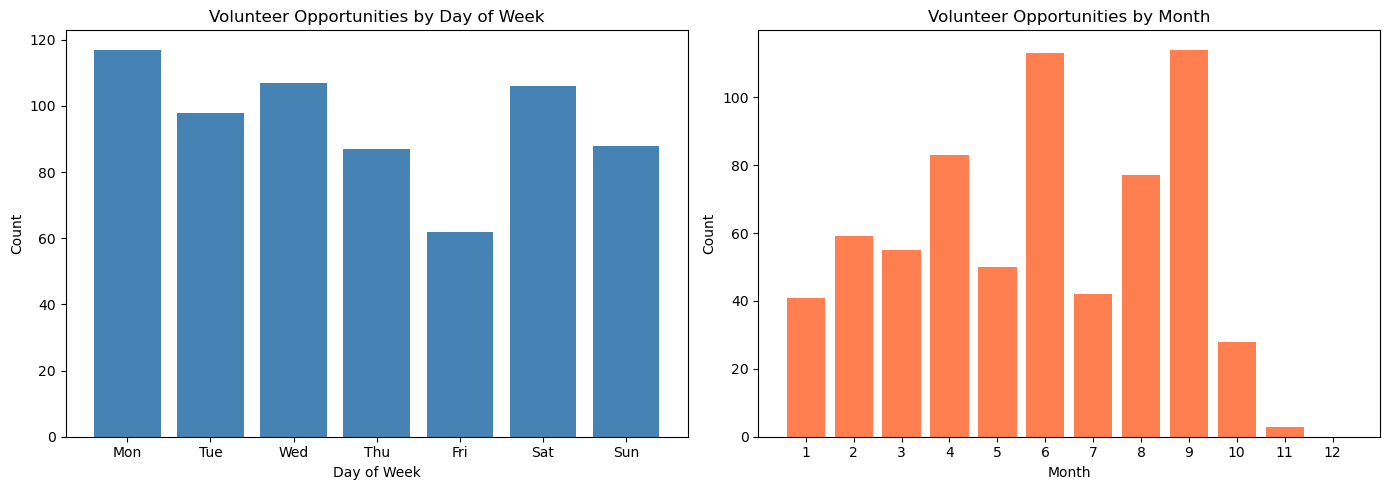

In [12]:
# Visualize opportunities by day of week
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Day of week distribution
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
day_counts = df_eng['start_dayofweek'].value_counts().sort_index()
axes[0].bar(day_names, day_counts.values, color='steelblue')
axes[0].set_title('Volunteer Opportunities by Day of Week')
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Count')

# Monthly distribution
month_counts = df_eng['start_month'].value_counts().sort_index()
axes[1].bar(range(1, 13), [month_counts.get(i, 0) for i in range(1, 13)], color='coral')
axes[1].set_title('Volunteer Opportunities by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Count')
axes[1].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

---

## 4. Text Feature Engineering

Text data requires special techniques to convert into numerical features that ML models can use.

### 4.1 Bag of Words (BoW)

The Bag of Words model represents text as a vector of word counts, ignoring grammar and word order.

![Bag of Words](https://miro.medium.com/v2/resize:fit:1400/1*cTt3HXIv2NZS5GnXP94fTg.png)

*Bag of Words converts text into numerical vectors based on word frequency.*

In [13]:
# Sample text data for demonstration
sample_texts = [
    "Volunteers needed for community garden project",
    "Help needed at food bank distribution center",
    "Community volunteers wanted for park cleanup",
    "Food distribution volunteers needed urgently"
]

# Create Bag of Words using CountVectorizer
count_vec = CountVectorizer()
bow_matrix = count_vec.fit_transform(sample_texts)

# Convert to DataFrame for better visualization
bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vec.get_feature_names_out(),
    index=[f'Doc {i+1}' for i in range(len(sample_texts))]
)

print("Bag of Words Representation:")
bow_df

Bag of Words Representation:


,at,bank,center,cleanup,community,distribution,food,for,garden,help,needed,park,project,urgently,volunteers,wanted
Doc 1,0,0,0,0,1,0,0,1,1,0,1,0,1,0,1,0
Doc 2,1,1,1,0,0,1,1,0,0,1,1,0,0,0,0,0
Doc 3,0,0,0,1,1,0,0,1,0,0,0,1,0,0,1,1
Doc 4,0,0,0,0,0,1,1,0,0,0,1,0,0,1,1,0


### 4.2 TF-IDF (Term Frequency-Inverse Document Frequency)

TF-IDF weighs words by their importance - words that appear frequently in one document but rarely across all documents are given higher weight.

**Formula:**
- **TF (Term Frequency)** = (Number of times term t appears in document) / (Total terms in document)
- **IDF (Inverse Document Frequency)** = log(Total documents / Documents containing term t)
- **TF-IDF** = TF x IDF

![TF-IDF](https://miro.medium.com/v2/resize:fit:1400/1*qQgnyPLDIkUmeZKN2_ZWbQ.png)

*TF-IDF gives higher weight to distinctive words.*

In [14]:
# Create TF-IDF representation
tfidf_vec = TfidfVectorizer()
tfidf_matrix = tfidf_vec.fit_transform(sample_texts)

# Convert to DataFrame
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray().round(3),
    columns=tfidf_vec.get_feature_names_out(),
    index=[f'Doc {i+1}' for i in range(len(sample_texts))]
)

print("TF-IDF Representation:")
tfidf_df

TF-IDF Representation:


,at,bank,center,cleanup,community,distribution,food,for,garden,help,needed,park,project,urgently,volunteers,wanted
Doc 1,0.000,0.000,0.000,0.000,0.391,0.000,0.000,0.391,0.496,0.000,0.317,0.000,0.496,0.000,0.317,0.000
Doc 2,0.421,0.421,0.421,0.000,0.000,0.332,0.332,0.000,0.000,0.421,0.269,0.000,0.000,0.000,0.000,0.000
Doc 3,0.000,0.000,0.000,0.464,0.366,0.000,0.000,0.366,0.000,0.000,0.000,0.464,0.000,0.000,0.296,0.464
Doc 4,0.000,0.000,0.000,0.000,0.000,0.451,0.451,0.000,0.000,0.000,0.365,0.000,0.000,0.572,0.365,0.000


In [15]:
# Apply TF-IDF to the actual dataset 'title' column
# Limit to top 10 features for demonstration
tfidf_titles = TfidfVectorizer(max_features=10, stop_words='english')
title_features = tfidf_titles.fit_transform(df_eng['title'].fillna(''))

# Create DataFrame with TF-IDF features
title_tfidf_df = pd.DataFrame(
    title_features.toarray(),
    columns=[f'tfidf_{word}' for word in tfidf_titles.get_feature_names_out()]
)

print(f"TF-IDF features shape: {title_tfidf_df.shape}")
print("\nTop TF-IDF features from titles:")
print(tfidf_titles.get_feature_names_out())
title_tfidf_df.head()

TF-IDF features shape: (665, 10)

Top TF-IDF features from titles:
['2011' 'assistant' 'help' 'instructor' 'needed' 'new' 'professionals'
 'queens' 'volunteer' 'volunteers']


,tfidf_2011,tfidf_assistant,tfidf_help,tfidf_instructor,tfidf_needed,tfidf_new,tfidf_professionals,tfidf_queens,tfidf_volunteer,tfidf_volunteers
0,0.0,0.0,0.0,0.0,0.722319,0.0,0.0,0.0,0.0,0.69156
1,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.00000
2,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.00000
3,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.00000
4,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.00000


---

## 5. Binning and Discretization

Binning transforms continuous variables into categorical bins, which can help capture non-linear relationships.

![Binning](https://miro.medium.com/v2/resize:fit:1200/1*W51t4_1zyoLg1IhTbR1Xdw.png)

*Converting continuous data into discrete bins.*

In [16]:
# Bin the 'hits' column into categories
df_eng['hits_category'] = pd.cut(
    df_eng['hits'],
    bins=[0, 100, 500, 1000, float('inf')],
    labels=['Low', 'Medium', 'High', 'Very High']
)

print("Hits binned into categories:")
print(df_eng['hits_category'].value_counts())

Hits binned into categories:
hits_category
Medium       390
Low          160
High          76
Very High     36
Name: count, dtype: int64


In [17]:
# Quantile-based binning (equal-sized bins)
df_eng['hits_quantile'] = pd.qcut(
    df_eng['hits'],
    q=4,
    labels=['Q1', 'Q2', 'Q3', 'Q4']
)

print("Hits binned by quantiles:")
print(df_eng['hits_quantile'].value_counts())

Hits binned by quantiles:
hits_quantile
Q1    167
Q2    166
Q3    166
Q4    166
Name: count, dtype: int64


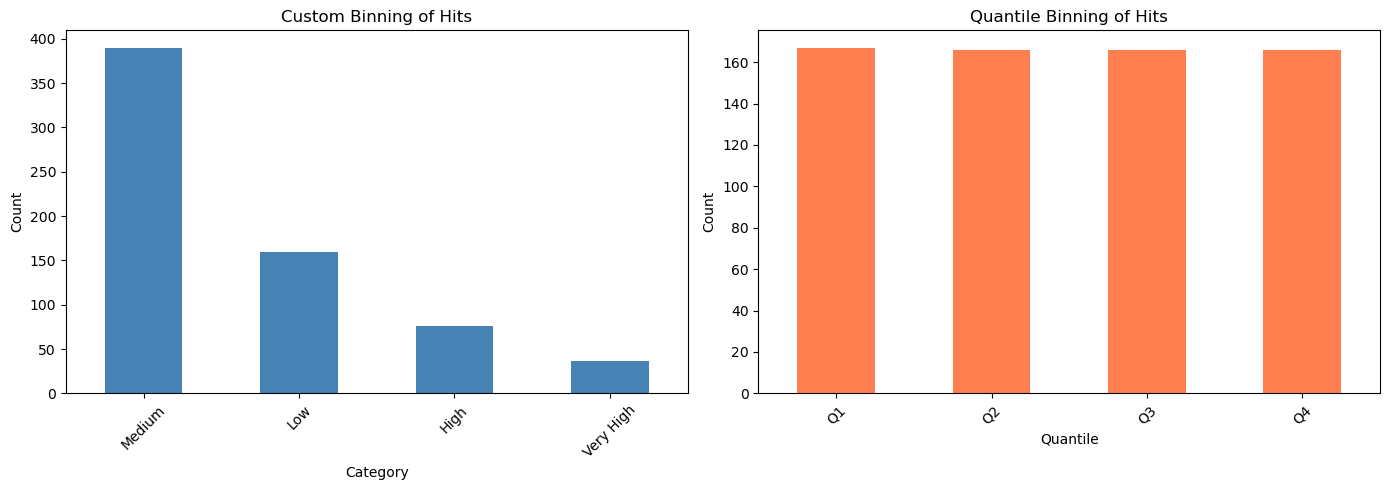

In [18]:
# Visualize the binning
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Custom bins
df_eng['hits_category'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Custom Binning of Hits')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Quantile bins
df_eng['hits_quantile'].value_counts().plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Quantile Binning of Hits')
axes[1].set_xlabel('Quantile')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

---

## 6. Polynomial Features

Polynomial features create interactions and higher-order terms to capture non-linear relationships.

In [19]:
# Create polynomial features from hits and vol_requests
poly = PolynomialFeatures(degree=2, include_bias=False)
sample_data = df_eng[['hits', 'vol_requests']].fillna(0).head(5)

poly_features = poly.fit_transform(sample_data)
poly_df = pd.DataFrame(
    poly_features,
    columns=poly.get_feature_names_out(['hits', 'vol_requests'])
)

print("Polynomial Features (degree=2):")
poly_df

Polynomial Features (degree=2):


,hits,vol_requests,hits^2,hits vol_requests,vol_requests^2
0,737.0,50.0,543169.0,36850.0,2500.0
1,22.0,2.0,484.0,44.0,4.0
2,62.0,20.0,3844.0,1240.0,400.0
3,14.0,500.0,196.0,7000.0,250000.0
4,31.0,15.0,961.0,465.0,225.0


---

## 7. Summary of Engineered Features

Let us review all the features we have created:

In [20]:
# List all new features created
original_cols = set(df.columns)
new_cols = [col for col in df_eng.columns if col not in original_cols]

print(f"Total original features: {len(original_cols)}")
print(f"Total new features created: {len(new_cols)}")
print(f"Total features now: {len(df_eng.columns)}")
print("\nNew features created:")
for i, col in enumerate(new_cols, 1):
    print(f"  {i}. {col}")

Total original features: 35
Total new features created: 15
Total features now: 50

New features created:
  1. hits_per_request
  2. high_engagement
  3. title_length
  4. title_word_count
  5. summary_length
  6. start_year
  7. start_month
  8. start_day
  9. start_dayofweek
  10. start_is_weekend
  11. start_quarter
  12. duration_days
  13. days_to_start
  14. hits_category
  15. hits_quantile


---

## Exercises

### Exercise 1: Create New Features
Create a feature called `title_has_urgent` that is 1 if the title contains the word "urgent" (case-insensitive) and 0 otherwise.

In [21]:
# Your code here
# df_eng['title_has_urgent'] = ...

### Exercise 2: DateTime Features
Extract the day name (e.g., 'Monday', 'Tuesday') from the `start_date_date` column.

In [22]:
# Your code here
# df_eng['start_day_name'] = ...

### Exercise 3: Binning
Create bins for `vol_requests` with categories: 'Few' (1-10), 'Moderate' (11-50), 'Many' (51-100), 'Large Scale' (100+).

In [23]:
# Your code here
# df_eng['volunteer_scale'] = ...

### Exercise 4: Text Features
Apply Bag of Words to the `summary` column and extract the top 5 most common words.

In [24]:
# Your code here

---

## Key Takeaways

1. **Feature Engineering is crucial** - It can make or break your ML model's performance
2. **Domain knowledge helps** - Understanding your data leads to better features
3. **DateTime features are rich** - Extract year, month, day, weekday, duration, etc.
4. **Text requires conversion** - Use BoW or TF-IDF to convert text to numbers
5. **Binning captures non-linearity** - Discretization can help certain models
6. **Polynomial features** - Capture interactions between variables

### Related Chapters

For more specialized preprocessing techniques, see:
- **Chapter 2: Feature Scaling** - StandardScaler, MinMaxScaler, RobustScaler
- **Chapter 4: Categorical Encoding** - One-Hot, Label, Ordinal, Frequency encoding

---

## Additional Resources

- [Scikit-learn Preprocessing](https://scikit-learn.org/stable/modules/preprocessing.html)
- [Feature Engineering for Machine Learning by Alice Zheng](https://www.oreilly.com/library/view/feature-engineering-for/9781491953235/)
- [Kaggle Feature Engineering Course](https://www.kaggle.com/learn/feature-engineering)

---

*End of Chapter 3: Feature Engineering*

---

## How this is used in real work

This is where most real accuracy comes from, and it is the part that does not transfer between problems. `dayofweek` on a transaction, `days_since_last_seen` on a user, TF-IDF on a support ticket: the library calls are trivial and knowing which one to reach for is the job.

## Where this goes next

**C3b** for anything with a time axis. **C4** encodes what is still text.